In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
housing = fetch_california_housing(as_frame=True) # downloads once, then cached on disk
df = housing.frame.copy()
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
df.info()       # column names, data types, non-null counts
df.describe()   # count, mean, std, min, quartiles, max for every column

In [ ]:
df.isna().sum()     # missing values per column

In [ ]:
df.hist(bins=40, figsize=(13,9))
plt.tight_layout()
plt.show()

In [ ]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()
corr["MedHouseVal"].sort_values(ascending=False)

In [ ]:
df.plot(kind="scatter", x="Longitude", y="Latitude", c="MedHouseVal", cmap="viridis",
        s=df["Population"] / 100, alpha=0.4, figsize=(8, 6), sharex=False)
plt.show()


In [ ]:
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x="MedInc", y="MedHouseVal", alpha=0.4)
plt.show()
print((df["MedHouseVal"] >= 5.0).sum(), "districts sit at the price cap")
df[["AveRooms","AveOccup"]].describe()

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="MedHouseVal") # features: every column except the target
y = df["MedHouseVal"] # target

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape) # (16512, 8) (4128, 8)
print(y_train.mean().round(3), y_test.mean().round(3)) # similar means: a sanity check


(16512, 8) (4128, 8)
2.072 2.055


In [ ]:
# This is a test data to learn about handling missing values and stuff not the real trainnig data the real one does not have any missing data


# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import OneHotEncoder, StandardScaler

# toy = pd.DataFrame({"sqft": [1200, None, 900, 1500],
#                 "city": ["A", "B", None, "A"]})

# numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
#                 ("scale", StandardScaler())])
# categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
#                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

# pre = ColumnTransformer([("num", numeric, ["sqft"]),
#                         ("cat", categorical, ["city"])])
# print(pre.fit_transform(toy).round(2))
# print(pre.get_feature_names_out())

In [5]:
from src.features import add_features, build_pipeline, RAW_FEATURES
add_features(X_train).head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,BedroomRatio,RoomsPerPerson,LogPopulation
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03,0.200576,1.359130,7.741099
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16,0.232703,2.573820,7.181592
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48,0.174486,2.073224,6.820016
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11,0.258269,1.002116,7.257708
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80,0.180940,2.725400,6.774224


In [6]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
def evaluate(name, model):
    """Cross-validate a model on the TRAINING set and store the average scores."""
    res = cross_validate(
        model, X_train, y_train, cv=cv, return_train_score=True,
        scoring={"rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error",
                "r2": "r2"},
     )
    row = {"model": name,
            "train_rmse": abs(res["train_rmse"].mean()),
            "cv_rmse": -res["test_rmse"].mean(),
            "cv_mae": -res["test_mae"].mean(),
            "cv_r2": res["test_r2"].mean()}
    results.append(row)
    return pd.DataFrame([row]).round(3)

evaluate("baseline (always the mean)", build_pipeline(DummyRegressor(strategy="mean")))


,model,train_rmse,cv_rmse,cv_mae,cv_r2
0,baseline (always the mean),1.156,1.156,0.914,-0.0


In [7]:
from sklearn.linear_model import LinearRegression, Ridge

evaluate("linear regression", build_pipeline(LinearRegression()))
evaluate("ridge (alpha=1)", build_pipeline(Ridge(alpha=1.0)))

,model,train_rmse,cv_rmse,cv_mae,cv_r2
0,ridge (alpha=1),0.675,0.681,0.484,0.652


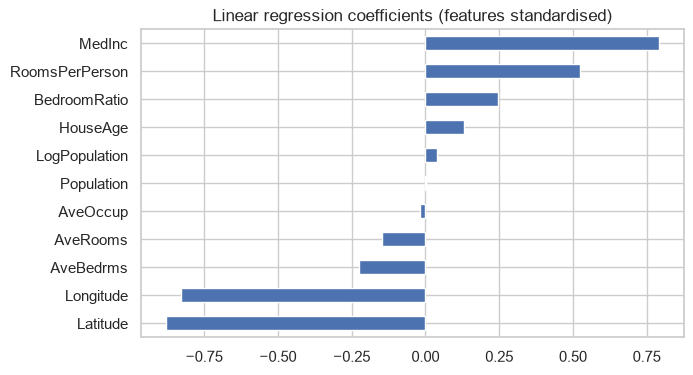

In [8]:
lin = build_pipeline(LinearRegression()).fit(X_train, y_train)

names = add_features(X_train).columns # names AFTER feature engineering
coefs = pd.Series(lin.named_steps["model"].coef_, index=names).sort_values()
coefs.plot(kind="barh", figsize=(7, 4))
plt.title("Linear regression coefficients (features standardised)")
plt.show()


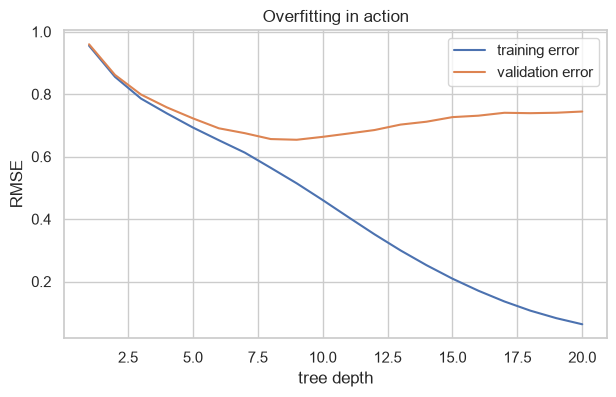

best depth: 9


In [ ]:
from sklearn.tree import DecisionTreeRegressor

depths = range(1, 21)
train_rmse, val_rmse = [], []
for d in depths:
    res = cross_validate(
        build_pipeline(DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)),
        X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True)
    train_rmse.append(-res["train_score"].mean())
    val_rmse.append(-res["test_score"].mean())
 
plt.figure(figsize=(7, 4))
plt.plot(depths, train_rmse, label="training error")
plt.plot(depths, val_rmse, label="validation error")
plt.xlabel("tree depth"); plt.ylabel("RMSE"); plt.legend(); plt.title("Overfitting in action")
plt.show()

best_depth = list(depths)[int(np.argmin(val_rmse))]
print("best depth:", best_depth)


In [15]:
evaluate("decision tree (no limit)", build_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)))
evaluate(f"decision tree (depth {best_depth})",
    build_pipeline(DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE)))

,model,train_rmse,cv_rmse,cv_mae,cv_r2
0,decision tree (depth 9),0.514,0.654,0.442,0.68


In [ ]:
'''Non linear models comparision with linear regression :Decision trees, random forests and
    gradient boosting'''
    
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

evaluate("random forest",
        build_pipeline(RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                            n_jobs=-1, random_state=RANDOM_STATE)))
evaluate("hist gradient boosting", build_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE)))

pd.DataFrame(results).round(3).sort_values("cv_rmse")

,model,train_rmse,cv_rmse,cv_mae,cv_r2
12,hist gradient boosting,0.387,0.469,0.314,0.835
11,random forest,0.236,0.511,0.334,0.804
6,decision tree (depth 9),0.514,0.654,0.442,0.680
4,decision tree (depth 9),0.514,0.654,0.442,0.680
8,decision tree (depth 9),0.514,0.654,0.442,0.680
10,decision tree (depth 9),0.514,0.654,0.442,0.680
1,linear regression,0.675,0.681,0.484,0.652
2,ridge (alpha=1),0.675,0.681,0.484,0.652
9,decision tree (no limit),0.000,0.748,0.480,0.581
7,decision tree (no limit),0.000,0.748,0.480,0.581


In [17]:
# Tuning

from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_leaf_nodes": randint(15, 80),
    "model__min_samples_leaf": randint(10, 80),
    "model__l2_regularization": loguniform(1e-3, 10),
}

search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingRegressor(max_iter=500, random_state=RANDOM_STATE)),
    param_distributions=param_distributions,
    n_iter=20, # 20 random combinations
    cv=cv, # the same 5 folds as before
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train) # trains 20 x 5 = 100 models

print("best CV RMSE:", round(-search.best_score_, 3))
print(search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
best CV RMSE: 0.459
{'model__l2_regularization': np.float64(0.039759772143180966), 'model__learning_rate': np.float64(0.022694105750550787), 'model__max_leaf_nodes': 74, 'model__min_samples_leaf': 24}


In [18]:
# Inspect the runner-up combinations to see how sensitive the result is for the above one:

cv_table = pd.DataFrame(search.cv_results_)
cols = ["mean_test_score", "param_model__learning_rate",
 "param_model__max_leaf_nodes", "param_model__min_samples_leaf"]
cv_table.sort_values("mean_test_score", ascending=False)[cols].head(5)

,mean_test_score,param_model__learning_rate,param_model__max_leaf_nodes,param_model__min_samples_leaf
5,-0.459371,0.022694,74,24
15,-0.459578,0.048425,76,49
17,-0.459601,0.042799,55,38
7,-0.460135,0.070792,65,16
13,-0.460211,0.032994,77,27


In [ ]:
# the final test and compare this to the tuned cv model if it is worse suspect leakage

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best = search.best_estimator_
y_pred = best.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Test RMSE: {test_rmse:.3f} (about ${test_rmse * 100_000:,.0f})")
print(f"Test MAE : {test_mae:.3f} (about ${test_mae * 100_000:,.0f})")
print(f"Test R2 : {test_r2:.3f}")

Test RMSE: 0.453 (about $45,311)
Test MAE : 0.296 (about $29,619)
Test R2 : 0.843


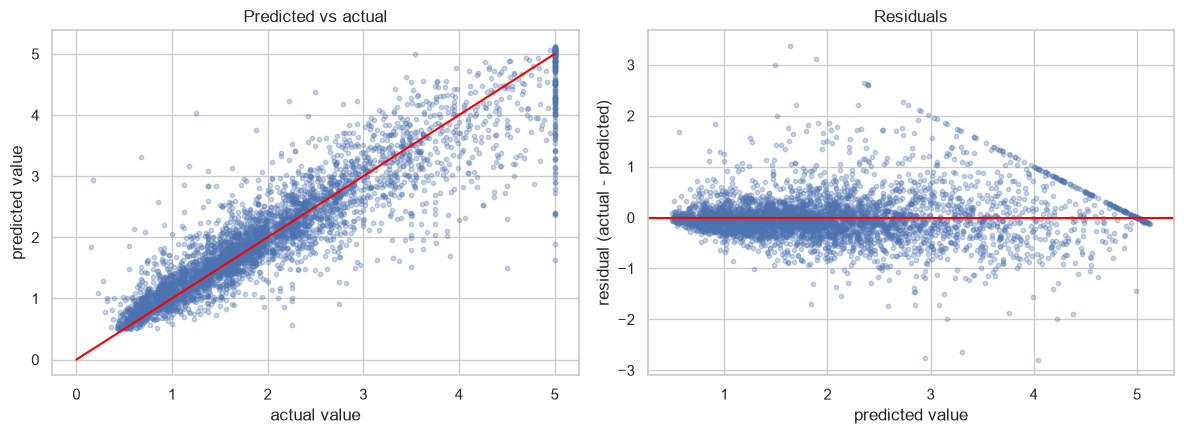

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_test, y_pred, alpha=0.3, s=10)
axes[0].plot([0, 5], [0, 5], color="red") # perfect predictions lie on this line
axes[0].set(xlabel="actual value", ylabel="predicted value", title="Predicted vs actual")

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.3, s=10)
axes[1].axhline(0, color="red")
axes[1].set(xlabel="predicted value", ylabel="residual (actual - predicted)", title="Residuals")
plt.tight_layout(); plt.show()


In [21]:
# The worst predictions

errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = y_pred
errors["abs_error"] = (errors["actual"] - errors["predicted"]).abs()

errors.sort_values("abs_error", ascending=False).head(10) # the ten worst predictions

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,actual,predicted,abs_error
6688,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,5.00001,1.632942,3.367068
12389,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,1.886835,3.113175
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,1.494975,3.005025
20349,7.3004,32.0,5.724138,0.758621,63.0,2.172414,34.17,-119.08,1.25000,4.040770,2.790770
5887,2.3667,39.0,3.572464,1.217391,259.0,1.876812,34.15,-118.33,0.17500,2.943500,2.768500
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,2.358658,2.641352
4548,7.5752,52.0,3.142857,1.000000,55.0,7.857143,34.02,-118.21,0.67500,3.308129,2.633129
20325,4.5833,21.0,7.278431,1.082353,863.0,3.384314,34.28,-119.04,5.00001,2.386288,2.613722
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,2.394882,2.605128
10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,2.395797,2.604213


In [22]:
# error by price band

errors["price_band"] = pd.cut(errors["actual"], [0, 1, 2, 3, 4, 5.01],
 labels=["< 100k", "100-200k", "200-300k", "300-400k", "400-500k"])
errors.groupby("price_band", observed=True)["abs_error"].agg(["mean", "count"]).round(3)


,mean,count
price_band,,
< 100k,0.204,739
100-200k,0.222,1682
200-300k,0.312,956
300-400k,0.469,412
400-500k,0.613,339


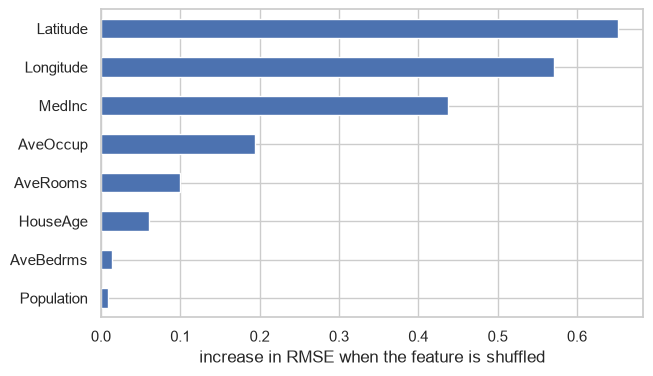

In [24]:
from sklearn.inspection import permutation_importance

r = permutation_importance(best, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
 scoring="neg_root_mean_squared_error", n_jobs=-1)
importance = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
importance.plot(kind="barh", figsize=(7, 4))
plt.xlabel("increase in RMSE when the feature is shuffled")
plt.show()
